# DermaScan — Klasifikasi Severity Jerawat dengan MobileNetV3-Large

Notebook Google Colab untuk mencoba dataset [Layered-Labs/ACNE04](https://huggingface.co/datasets/Layered-Labs/ACNE04).

## 1. Instalasi dan pemeriksaan GPU

In [ ]:
!pip -q install datasets pillow scikit-learn

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("Versi TensorFlow:", tf.__version__)
print("GPU tersedia:", tf.config.list_physical_devices("GPU"))
tf.keras.utils.set_random_seed(42)

Versi TensorFlow: 2.21.0
GPU tersedia: []


## 2. Download dataset ACNE04 dari Hugging Face

In [ ]:
from datasets import load_dataset

data = load_dataset("Layered-Labs/ACNE04", split="train")
print("Total gambar:", len(data))
print("Kolom dataset:", data.column_names)
print("Contoh label level:", data[0]["level"])
print("Contoh label severity:", data[0]["severity"])

README.md:   0%|          | 0.00/8.60k [00:00<?, ?B/s]

data/train-00000-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  415MB            

data/train-00000-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  410MB            

data/train-00001-of-00003.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00003.parquet: reconstructing file:   0%|          |  0.00B /  305MB            

data/train-00002-of-00003.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1457 [00:00<?, ? examples/s]

Total gambar: 1457
Kolom dataset: ['image', 'file_name', 'level', 'severity', 'lesion_count_label', 'num_lesions_annotated', 'lesion_boxes', 'split', 'fold_0_split', 'fold_1_split', 'fold_2_split', 'fold_3_split', 'fold_4_split']
Contoh label level: 0
Contoh label severity: mild


## 3. Lihat beberapa gambar dan label
Gunakan kolom `level` sebagai target utama: 0 ringan, 1 sedang, 2 berat, 3 sangat berat.

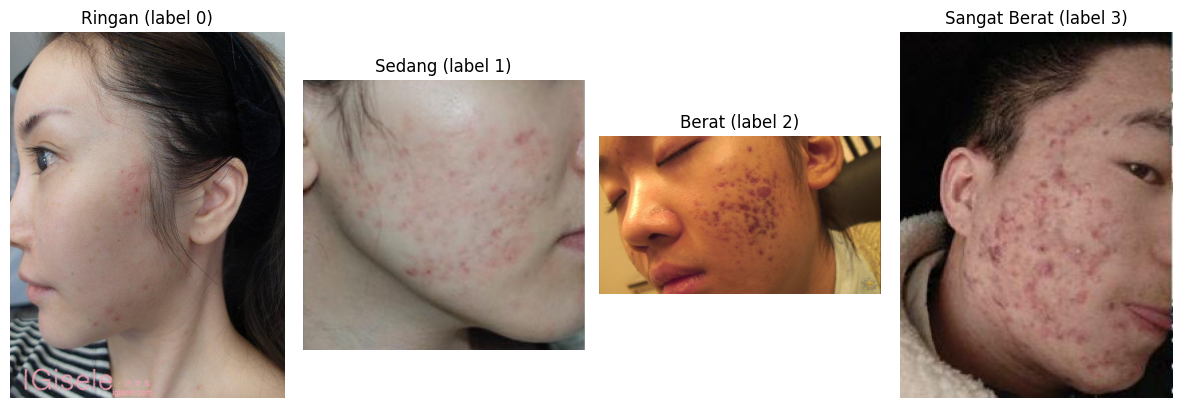

In [ ]:
kelas = ["Ringan", "Sedang", "Berat", "Sangat Berat"]

fig, axes = plt.subplots(1, 4, figsize=(12, 4))
for label in range(4):
    indeks = next(i for i, value in enumerate(data["level"]) if value == label)
    row = data[indeks]
    axes[label].imshow(row["image"])
    axes[label].set_title(f"{kelas[label]} (label {label})")
    axes[label].axis("off")
plt.tight_layout()
plt.show()

## 4. Gunakan train/test resmi dan pisahkan validation dari train
Pembagian ini menjaga agar data test tidak digunakan saat pelatihan maupun pemilihan model. Validation diambil secara stratified (20% dari data train resmi).

In [ ]:
from sklearn.model_selection import train_test_split

idx_train = [i for i, s in enumerate(data["split"]) if s == "train"]
idx_test = [i for i, s in enumerate(data["split"]) if s == "test"]

train_awal = data.select(idx_train)
test_data = data.select(idx_test)

idx_latih, idx_valid = train_test_split(
    np.arange(len(train_awal)),
    test_size=0.20,
    random_state=42,
    stratify=np.array(train_awal["level"])
)
train_data = train_awal.select(idx_latih.tolist())
val_data = train_awal.select(idx_valid.tolist())

print("Training  :", len(train_data))
print("Validation:", len(val_data))
print("Testing   :", len(test_data))

Training  : 932
Validation: 233
Testing   : 292


## 5. Preprocessing gambar
Semua gambar diubah menjadi RGB 224×224.

In [ ]:
from PIL import Image, ImageOps

UKURAN = (256, 256)

def siapkan_data(dataset):
    gambar = []
    label = []
    for row in dataset:
        img = ImageOps.pad(row["image"].convert("RGB"), UKURAN, color=(0, 0, 0))
        gambar.append(np.asarray(img, dtype=np.uint8))
        label.append(int(row["level"]))
    return np.stack(gambar), np.array(label, dtype=np.int32)

X_train, y_train = siapkan_data(train_data)
X_val, y_val = siapkan_data(val_data)
X_test, y_test = siapkan_data(test_data)

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val  :", X_val.shape, "y_val  :", y_val.shape)
print("X_test :", X_test.shape, "y_test :", y_test.shape)

X_train: (932, 256, 256, 3) y_train: (932,)
X_val  : (233, 256, 256, 3) y_val  : (233,)
X_test : (292, 256, 256, 3) y_test : (292,)


## 6. Bangun model MobileNetV3-Large (transfer learning)
Bobot awal berasal dari ImageNet, lapisan dasar dibekukan dahulu, dan ditambah output 4 kelas. Augmentasi ringan aktif hanya ketika training.

In [ ]:
base_model = tf.keras.applications.MobileNetV3Large(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
    include_preprocessing=True
)
base_model.trainable = False

inputs = tf.keras.Input(shape=(224, 224, 3))
x = tf.keras.layers.RandomFlip("horizontal")(inputs)
x = tf.keras.layers.RandomRotation(0.04)(x)
x = tf.keras.layers.RandomZoom(0.08)(x)
x = base_model(x, training=False)
x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.3)(x)
outputs = tf.keras.layers.Dense(4, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)
model.summary()

12683000/12683000 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 224, 224, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ MobileNetV3Large (Functional)   │ (None, 7, 7, 960)      │     2,996,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 960)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,000,196 (11.44 MB)

 Trainable params: 3,844 (15.02 KB)

 Non-trainable params: 2,996,352 (11.43 MB)

## 7. Hitung bobot kelas dan latih model
ACNE04 tidak seimbang. `class_weight` memberi bobot lebih besar pada kelas yang lebih jarang. Untuk percobaan awal gunakan 10 epoch dengan early stopping.

In [ ]:
from sklearn.utils.class_weight import compute_class_weight

kelas_angka = np.unique(y_train)
bobot = compute_class_weight(class_weight="balanced", classes=kelas_angka, y=y_train)
class_weights = {int(k): float(v) for k, v in zip(kelas_angka, bobot)}
print("Bobot kelas:", class_weights)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=16,
    class_weight=class_weights,
    callbacks=[tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )]
)

Bobot kelas: {0: 0.7103658536585366, 1: 0.5753086419753086, 2: 1.9914529914529915, 3: 2.841463414634146}
Epoch 1/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 55s 814ms/step - accuracy: 0.3305 - loss: 1.4415 - val_accuracy: 0.4292 - val_loss: 1.1975
Epoch 2/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 79s 766ms/step - accuracy: 0.4024 - loss: 1.2147 - val_accuracy: 0.4721 - val_loss: 1.1150
Epoch 3/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 79s 720ms/step - accuracy: 0.4345 - loss: 1.1184 - val_accuracy: 0.4549 - val_loss: 1.0926
Epoch 4/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 82s 714ms/step - accuracy: 0.4764 - loss: 1.0416 - val_accuracy: 0.5064 - val_loss: 1.0356
Epoch 5/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 45s 761ms/step - accuracy: 0.5107 - loss: 0.9773 - val_accuracy: 0.5365 - val_loss: 1.0106
Epoch 6/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 84s 790ms/step - accuracy: 0.5150 - loss: 0.9612 - val_accuracy: 0.5365 - val_loss: 0.9865
Epoch 7/10
59/59 ━━━━━━━━━━━━━━━━━━━━ 42s 716ms/step - accuracy: 0.5494 - loss: 0.9241 - val_accuracy: 0.5236 - val_loss:

## 8. Grafik accuracy dan loss
Validation yang jauh lebih buruk daripada training dapat menunjukkan overfitting.

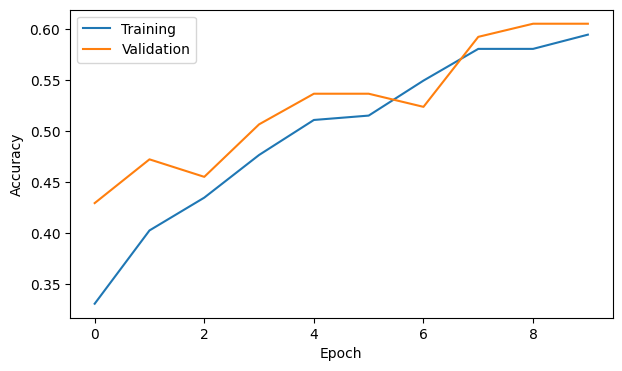

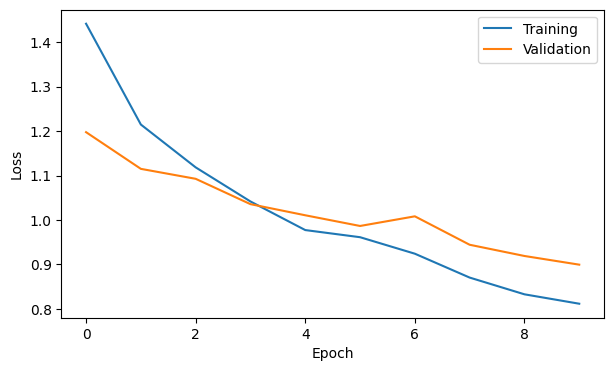

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## 9. Evaluasi akhir pada data test
Jalankan evaluasi setelah pilihan model selesai. Selain accuracy, perhatikan **macro F1** dan recall tiap kelas.

Test accuracy : 0.637
Test macro F1 : 0.6388

Laporan klasifikasi:

              precision    recall  f1-score   support

      Ringan       0.73      0.73      0.73       103
      Sedang       0.68      0.54      0.60       127
       Berat       0.36      0.58      0.44        36
Sangat Berat       0.73      0.85      0.79        26

    accuracy                           0.64       292
   macro avg       0.62      0.67      0.64       292
weighted avg       0.66      0.64      0.64       292



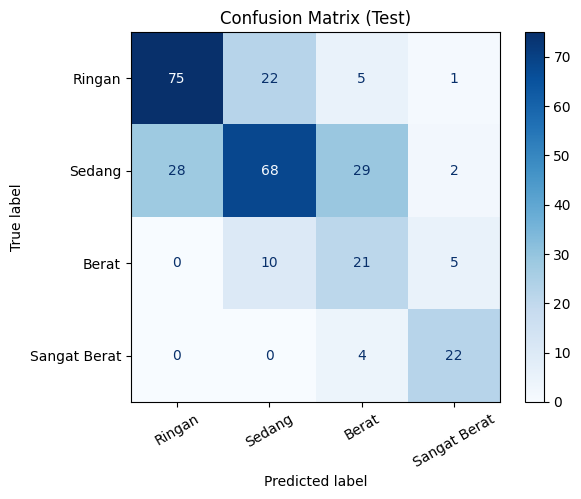

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

hasil_prob = model.predict(X_test, batch_size=16, verbose=0)
y_pred = np.argmax(hasil_prob, axis=1)

print("Test accuracy :", round(accuracy_score(y_test, y_pred), 4))
print("Test macro F1 :", round(f1_score(y_test, y_pred, average="macro"), 4))
print("\nLaporan klasifikasi:\n")
print(classification_report(y_test, y_pred, labels=[0,1,2,3],
                            target_names=kelas, zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0,1,2,3], display_labels=kelas,
    cmap="Blues", xticks_rotation=30
)
plt.title("Confusion Matrix (Test)")
plt.show()

In [ ]:
# Menyimpan model sebelum fine-tuning
model.save("dermascan_sebelum_finetuning.keras")

print("Model awal berhasil disimpan!")

Model awal berhasil disimpan!


In [ ]:
from sklearn.metrics import accuracy_score, f1_score
import numpy as np

# Prediksi pada data validation
prob_sebelum = model.predict(X_val, verbose=0)
pred_sebelum = np.argmax(prob_sebelum, axis=1)

# Hitung hasil awal
akurasi_sebelum = accuracy_score(y_val, pred_sebelum)
f1_sebelum = f1_score(y_val, pred_sebelum, average="macro")

print("Validation Accuracy:", round(akurasi_sebelum, 4))
print("Validation Macro F1:", round(f1_sebelum, 4))

Validation Accuracy: 0.6052
Validation Macro F1: 0.6176


In [ ]:
# Mengaktifkan kembali base model
base_model.trainable = True

# Membekukan semua lapisan kecuali 30 lapisan terakhir
for layer in base_model.layers[:-30]:
    layer.trainable = False

# BatchNormalization tetap dibekukan
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Melihat jumlah lapisan yang dapat dilatih
jumlah_trainable = sum(
    layer.trainable for layer in base_model.layers
)

print("Total lapisan base model:", len(base_model.layers))
print("Lapisan yang dapat dilatih:", jumlah_trainable)

Total lapisan base model: 187
Lapisan yang dapat dilatih: 24


In [ ]:
# Compile ulang model untuk fine-tuning
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00001
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Model siap untuk fine-tuning!")

Model siap untuk fine-tuning!


In [ ]:
# Fine-tuning model
history_fine = model.fit(
    X_train,
    y_train,

    validation_data=(X_val, y_val),

    epochs=12,
    batch_size=16,

    class_weight=class_weights,

    callbacks=[
        tf.keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=3,
            restore_best_weights=True
        )
    ]
)

Epoch 1/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 64s 911ms/step - accuracy: 0.5987 - loss: 0.7883 - val_accuracy: 0.6180 - val_loss: 0.9188
Epoch 2/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 53s 904ms/step - accuracy: 0.6395 - loss: 0.7267 - val_accuracy: 0.5923 - val_loss: 0.9067
Epoch 3/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 80s 873ms/step - accuracy: 0.6534 - loss: 0.7174 - val_accuracy: 0.5751 - val_loss: 0.8866
Epoch 4/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 50s 847ms/step - accuracy: 0.6599 - loss: 0.6927 - val_accuracy: 0.5966 - val_loss: 0.8698
Epoch 5/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 82s 848ms/step - accuracy: 0.6534 - loss: 0.6759 - val_accuracy: 0.5751 - val_loss: 0.8655
Epoch 6/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 50s 857ms/step - accuracy: 0.6491 - loss: 0.6570 - val_accuracy: 0.5880 - val_loss: 0.8576
Epoch 7/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 53s 901ms/step - accuracy: 0.6706 - loss: 0.6395 - val_accuracy: 0.5880 - val_loss: 0.8522
Epoch 8/12
59/59 ━━━━━━━━━━━━━━━━━━━━ 53s 902ms/step - accuracy: 0.6609 - loss: 0.6366 - val_accu

In [ ]:
# Prediksi setelah fine-tuning
prob_sesudah = model.predict(X_val, verbose=0)
pred_sesudah = np.argmax(prob_sesudah, axis=1)

# Hitung metrik
akurasi_sesudah = accuracy_score(y_val, pred_sesudah)
f1_sesudah = f1_score(
    y_val, pred_sesudah, average="macro"
)

# Bandingkan hasil
print("SEBELUM FINE-TUNING")
print("Accuracy:", round(akurasi_sebelum, 4))
print("Macro F1:", round(f1_sebelum, 4))

print("\nSETELAH FINE-TUNING")
print("Accuracy:", round(akurasi_sesudah, 4))
print("Macro F1:", round(f1_sesudah, 4))

SEBELUM FINE-TUNING
Accuracy: 0.6052
Macro F1: 0.6176

SETELAH FINE-TUNING
Accuracy: 0.6266
Macro F1: 0.6404


In [ ]:
# Memilih model berdasarkan hasil validation
if f1_sesudah >= f1_sebelum:
    print("Menggunakan model fine-tuning")
else:
    print("Kembali menggunakan model awal")
    model = tf.keras.models.load_model(
        "dermascan_sebelum_finetuning.keras"
    )

Menggunakan model fine-tuning


## 10. Coba prediksi satu gambar dari test set
Langkah ini berguna untuk memastikan alur inferensi sudah berjalan sebelum mencoba foto sendiri.

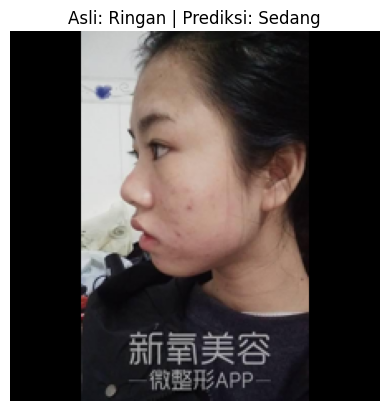

Ringan        : 27.89%
Sedang        : 44.39%
Berat         : 19.49%
Sangat Berat  : 8.24%


In [ ]:
nomor = 20
contoh = X_test[nomor]
prob = model.predict(contoh[np.newaxis, ...], verbose=0)[0]
pred = int(np.argmax(prob))

plt.imshow(contoh)
plt.axis("off")
plt.title(f"Asli: {kelas[y_test[nomor]]} | Prediksi: {kelas[pred]}")
plt.show()
for nama, p in zip(kelas, prob):
    print(f"{nama:14s}: {p:.2%}")

## 11. (Opsional) Unggah foto sendiri untuk diuji
Foto smartphone mungkin berbeda dari distribusi gambar dataset. Hasilnya adalah klasifikasi eksperimen, bukan diagnosis medis.

Saving test_jerawat_dama_1.jpeg to test_jerawat_dama_1 (1).jpeg
Prediksi severity: Berat
Ringan        : 17.15%
Sedang        : 40.41%
Berat         : 41.23%
Sangat Berat  : 1.21%


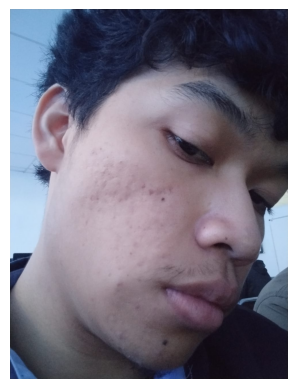

In [ ]:
from google.colab import files
from io import BytesIO

unggahan = files.upload()
nama_file = next(iter(unggahan))
foto = Image.open(BytesIO(unggahan[nama_file])).convert("RGB")
foto_input = ImageOps.pad(foto, UKURAN, color=(0, 0, 0))
arr = np.asarray(foto_input, dtype=np.float32)[np.newaxis, ...]

prob = model.predict(arr, verbose=0)[0]
print("Prediksi severity:", kelas[int(np.argmax(prob))])
for nama, p in zip(kelas, prob):
    print(f"{nama:14s}: {p:.2%}")

plt.imshow(foto)
plt.axis("off")
plt.show()

## 12. Simpan model Keras dan konversi menjadi TensorFlow Lite
Ekspor memakai optimasi bobot default. Input model yang diekspor harus diperiksa (umumnya float32 `[1,224,224,3]`, piksel 0–255).

In [ ]:
model.save("dermascan_mobilenetv3.keras")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
tflite_model = converter.convert()

with open("dermascan_mobilenetv3.tflite", "wb") as f:
    f.write(tflite_model)

with open("labels.txt", "w") as f:
    f.write("\n".join(kelas))

print("Berhasil membuat dermascan_mobilenetv3.tflite dan labels.txt")

## 13. Validasi model TFLite sebelum dipakai di Flutter
Menguji satu contoh test; hasilnya semestinya dekat dengan model Keras. Jika dtype/shape tidak sesuai, periksa output `get_input_details()`.

In [ ]:
interpreter = tf.lite.Interpreter(model_path="dermascan_mobilenetv3.tflite")
interpreter.allocate_tensors()
input_detail = interpreter.get_input_details()[0]
output_detail = interpreter.get_output_details()[0]

print("Input:", input_detail["shape"], input_detail["dtype"])
print("Output:", output_detail["shape"], output_detail["dtype"])

contoh_tflite = X_test[0:1].astype(input_detail["dtype"])
interpreter.set_tensor(input_detail["index"], contoh_tflite)
interpreter.invoke()
prob_tflite = interpreter.get_tensor(output_detail["index"])[0]
print("Prediksi Keras :", kelas[int(np.argmax(model.predict(X_test[0:1], verbose=0)[0]))])
print("Prediksi TFLite:", kelas[int(np.argmax(prob_tflite))])

## 14. Download model untuk Flutter

In [ ]:
from google.colab import files
files.download("dermascan_mobilenetv3.tflite")
files.download("labels.txt")

### Catatan penting
- Empat label tersebut **bukan** jenis jerawat (komedo/papula/pustula), melainkan tingkat keparahan.
- Tidak ada kelas "tanpa jerawat" pada model ini.
- Gunakan foto dan preprocessing yang konsisten antara Colab dan Flutter (resize dengan rasio dipertahankan dan padding hitam; input RGB 0–255, dengan dtype dari metadata model).
- Dataset bersifat akademik dan tidak ditujukan untuk diagnosis klinis.
- Langkah lanjutan bila performanya kurang memadai: lakukan fine-tuning sebagian lapisan MobileNetV3 dengan learning rate kecil, lalu uji ulang di test set tanpa menggunakannya untuk pemilihan hyperparameter.

**Sumber:** [ACNE04](https://huggingface.co/datasets/Layered-Labs/ACNE04), [Keras MobileNetV3](https://keras.io/api/applications/mobilenet/mobilenet_models/), [TensorFlow Lite conversion](https://ai.google.dev/edge/litert/conversion/tensorflow/quantization/post_training_integer_quant).